In [ ]:
pip -q install xgboost


In [ ]:
import pandas as pd
import numpy as np

CSV_PATH = "/content/drive/MyDrive/Đồ án tốt nghiệp/data.csv"

df = pd.read_csv(CSV_PATH, sep=";", encoding="utf-8-sig")

df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

time_candidates = ["local_time", "timestamp_local", "time", "datetime", "date_time"]
time_col = next((c for c in time_candidates if c in df.columns), None)
if time_col is None:
    raise ValueError(f"Không tìm thấy cột thời gian. Các cột hiện có: {df.columns.tolist()}")

aqi_candidates = ["aqi", "aqi_calc", "vn_aqi"]
aqi_col = next((c for c in aqi_candidates if c in df.columns), None)
if aqi_col is None:
    raise ValueError(f"Không tìm thấy cột AQI. Các cột hiện có: {df.columns.tolist()}")

df[time_col] = pd.to_datetime(df[time_col], errors="coerce")

# Lọc dòng lỗi thời gian / AQI
df = df.dropna(subset=[time_col, aqi_col]).copy()

# Sort theo thời gian
df = df.sort_values(time_col)

df["hour"] = df[time_col].dt.floor("h")

df_hourly = df.groupby("hour", as_index=False).agg(
    aqi=(aqi_col, "mean")
)

df_hourly["date_time"] = df_hourly["hour"].dt.strftime("%Y-%m-%d:%H")

df_hourly.head()

,hour,aqi,date_time
0,2025-01-01 01:00:00,186.0,2025-01-01:01
1,2025-01-01 02:00:00,181.0,2025-01-01:02
2,2025-01-01 03:00:00,178.0,2025-01-01:03
3,2025-01-01 04:00:00,177.0,2025-01-01:04
4,2025-01-01 05:00:00,179.0,2025-01-01:05


In [ ]:
LAGS = [1, 2, 3, 4, 5, 6, 7, 8, 12]

for k in LAGS:
    df_hourly[f"aqi_prev_{k}"] = df_hourly["aqi"].shift(k)

df_hourly["aqi_next_1"] = df_hourly["aqi"].shift(-1)

df_hourly.head(15)


,hour,aqi,date_time,aqi_prev_1,aqi_prev_2,aqi_prev_3,aqi_prev_4,aqi_prev_5,aqi_prev_6,aqi_prev_7,aqi_prev_8,aqi_prev_12,aqi_next_1
0,2025-01-01 01:00:00,186.0,2025-01-01:01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,181.0
1,2025-01-01 02:00:00,181.0,2025-01-01:02,186.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,178.0
2,2025-01-01 03:00:00,178.0,2025-01-01:03,181.0,186.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,177.0
3,2025-01-01 04:00:00,177.0,2025-01-01:04,178.0,181.0,186.0,NaN,NaN,NaN,NaN,NaN,NaN,179.0
4,2025-01-01 05:00:00,179.0,2025-01-01:05,177.0,178.0,181.0,186.0,NaN,NaN,NaN,NaN,NaN,184.0
5,2025-01-01 06:00:00,184.0,2025-01-01:06,179.0,177.0,178.0,181.0,186.0,NaN,NaN,NaN,NaN,189.0
6,2025-01-01 07:00:00,189.0,2025-01-01:07,184.0,179.0,177.0,178.0,181.0,186.0,NaN,NaN,NaN,210.0
7,2025-01-01 08:00:00,210.0,2025-01-01:08,189.0,184.0,179.0,177.0,178.0,181.0,186.0,NaN,NaN,221.0
8,2025-01-01 09:00:00,221.0,2025-01-01:09,210.0,189.0,184.0,179.0,177.0,178.0,181.0,186.0,NaN,226.0
9,2025-01-01 10:00:00,226.0,2025-01-01:10,221.0,210.0,189.0,184.0,179.0,177.0,178.0,181.0,NaN,225.0


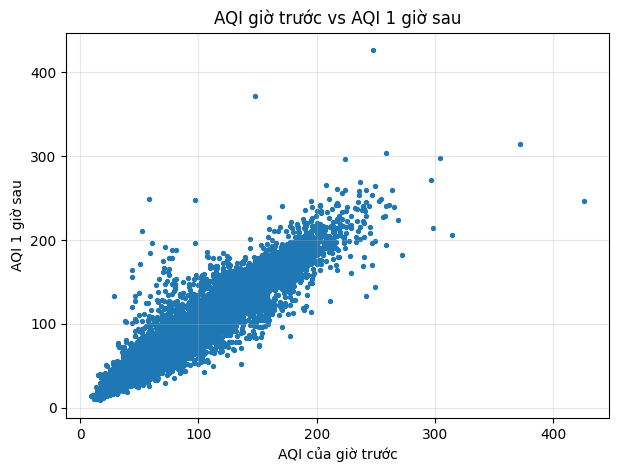

In [ ]:
import matplotlib.pyplot as plt

tmp = df_hourly.dropna(subset=["aqi_prev_1", "aqi_next_1"]).copy()

plt.figure(figsize=(7,5))
plt.scatter(tmp["aqi_prev_1"], tmp["aqi_next_1"], s=8)
plt.title("AQI giờ trước vs AQI 1 giờ sau")
plt.xlabel("AQI của giờ trước")
plt.ylabel("AQI 1 giờ sau")
plt.grid(True, alpha=0.3)
plt.show()


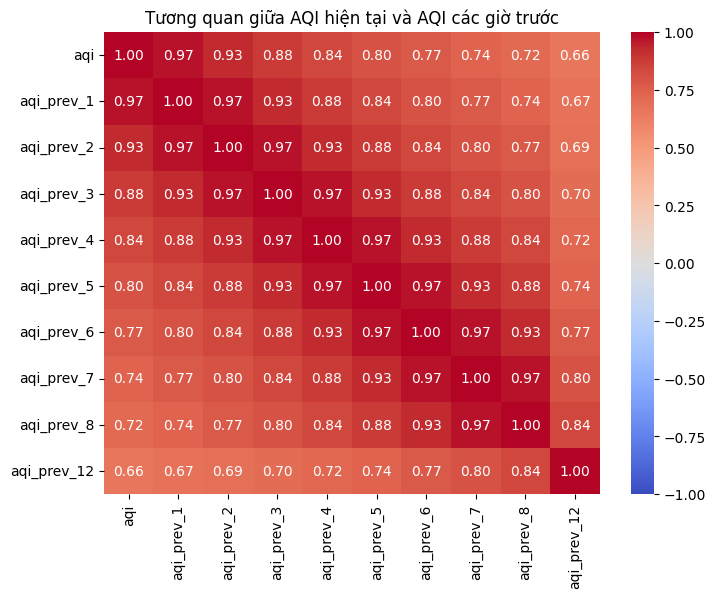

In [ ]:
import seaborn as sns

corr_cols = ["aqi"] + [f"aqi_prev_{k}" for k in LAGS]
corr_df = df_hourly[corr_cols].dropna().corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Tương quan giữa AQI hiện tại và AQI các giờ trước")
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

# tạo lag 1,2,3
df["aqi_prev_1"] = df["aqi"].shift(1)
df["aqi_prev_2"] = df["aqi"].shift(2)
df["aqi_prev_3"] = df["aqi"].shift(3)

df["aqi_next_1"] = df["aqi"].shift(-1)


data = df.dropna(subset=["aqi_prev_1","aqi_prev_2","aqi_prev_3","aqi_next_1"]).copy()

X = data[["aqi_prev_1","aqi_prev_2","aqi_prev_3"]]
y = data["aqi_next_1"]

print("Data shape:", data.shape)
data.head()


Data shape: (8756, 11)


,aqi,co,date_time,pm10,pm25,local_time,hour,aqi_prev_1,aqi_prev_2,aqi_prev_3,aqi_next_1
3,177,423.7,2025-01-01:04,116.0,115.0,2025-01-01 04:00:00,2025-01-01 04:00:00,178.0,181.0,186.0,179.0
4,179,447.0,2025-01-01:05,128.3,127.7,2025-01-01 05:00:00,2025-01-01 05:00:00,177.0,178.0,181.0,184.0
5,184,470.4,2025-01-01:06,140.7,140.3,2025-01-01 06:00:00,2025-01-01 06:00:00,179.0,177.0,178.0,189.0
6,189,493.7,2025-01-01:07,153.0,153.0,2025-01-01 07:00:00,2025-01-01 07:00:00,184.0,179.0,177.0,210.0
7,210,1310.0,2025-01-01:08,216.0,190.0,2025-01-01 08:00:00,2025-01-01 08:00:00,189.0,184.0,179.0,221.0


In [ ]:
split_ratio = 0.8
split_idx = int(len(data) * split_ratio)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (7004, 3) Test: (1752, 3)


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2  = r2_score(y_true, y_pred)
    return {"model": name, "MSE": mse, "MAE": mae, "R2": r2}


In [ ]:
results = []

# Baseline: dự đoán AQI(t+1) = AQI(t)
y_pred_base = X_test["aqi_prev_1"].values
results.append(evaluate("Baseline (AQI_t -> AQI_t+1)", y_test, y_pred_base))


In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
results.append(evaluate("Multiple Linear Regression (lags 1-3)", y_test, y_pred_lr))


In [ ]:
# ===== Export mô hình Linear Regression sang file .h để dùng cho ESP32 =====

import numpy as np
from google.colab import files

coefficients = np.array(lr.coef_, dtype=float).flatten()
intercept = float(lr.intercept_)

header_filename = "linear_regression_model.h"

with open(header_filename, "w", encoding="utf-8") as f:
    f.write("#ifndef LINEAR_REGRESSION_MODEL_H\n")
    f.write("#define LINEAR_REGRESSION_MODEL_H\n\n")

    f.write(f"#define NUM_FEATURES {len(coefficients)}\n\n")
    try:
        feature_names = list(X.columns)
        f.write("// Feature order used during training:\n")
        for i, name in enumerate(feature_names):
            f.write(f"// [{i}] {name}\n")
        f.write("\n")
    except:
        f.write("// Feature order used during training: unknown (X is not a DataFrame)\n\n")

    # Hệ số
    f.write("const float coefficients[NUM_FEATURES] = {")
    f.write(", ".join([f"{coef:.6f}f" for coef in coefficients]))
    f.write("};\n\n")

    # Intercept
    f.write(f"const float intercept = {intercept:.6f}f;\n\n")

    # Hàm predict
    f.write("float predict_aqi(const float features[NUM_FEATURES]) {\n")
    f.write("    float result = intercept;\n")
    f.write("    for (int i = 0; i < NUM_FEATURES; i++) {\n")
    f.write("        result += coefficients[i] * features[i];\n")
    f.write("    }\n")
    f.write("    return result;\n")
    f.write("}\n\n")

    f.write("#endif // LINEAR_REGRESSION_MODEL_H\n")

print(f"Đã tạo file: {header_filename}")

print("Coefficients:", coefficients)
print("Intercept:", intercept)


Đã tạo file: linear_regression_model.h
Coefficients: [ 1.17005969 -0.23266175 -0.03172454]
Intercept: 8.78213738026983


In [ ]:
print(X.columns.tolist())

['aqi_prev_1', 'aqi_prev_2', 'aqi_prev_3']


In [ ]:
files.download(header_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

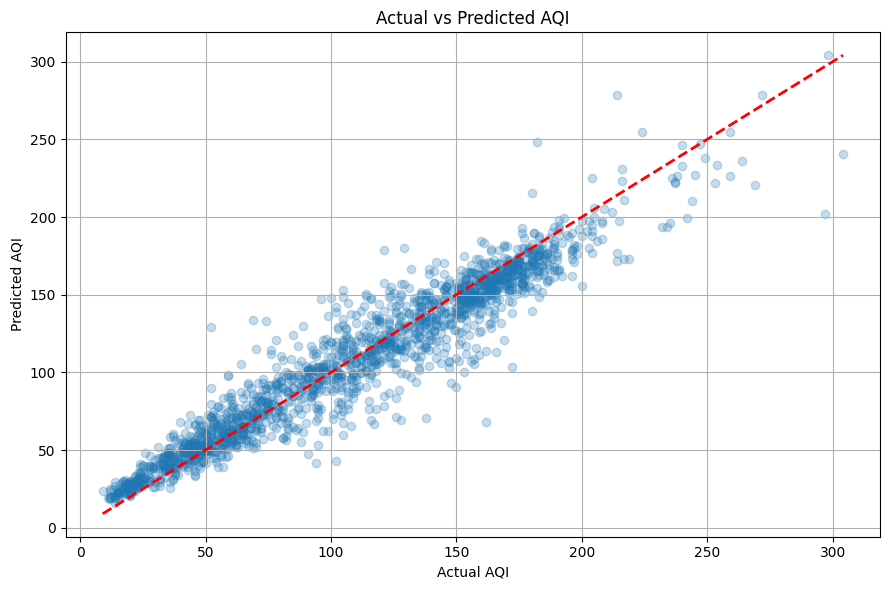

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.25)

# 4) Vẽ đường tham chiếu y = x (nét đứt đỏ)
min_val = float(min(np.min(y_test), np.min(y_pred_lr)))
max_val = float(max(np.max(y_test), np.max(y_pred_lr)))
plt.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2)

plt.title("Actual vs Predicted AQI")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.grid(True)
plt.tight_layout()
plt.show()

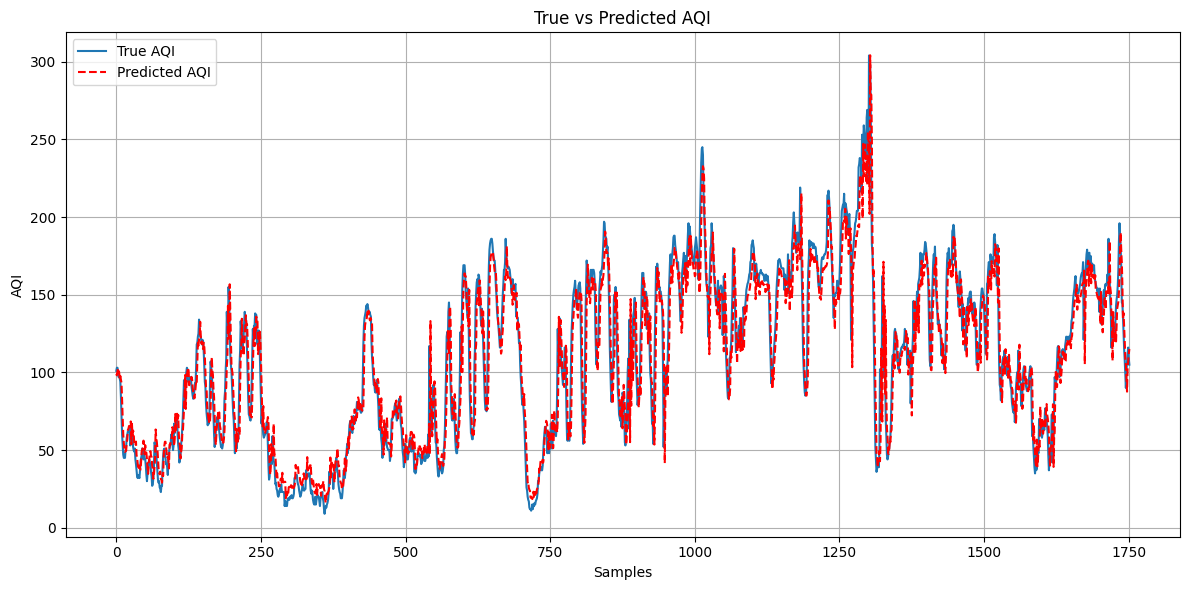

In [ ]:


plt.figure(figsize=(12, 6))
plt.plot(y_test.reset_index(drop=True), label="True AQI")          # xanh mặc định
plt.plot(pd.Series(y_pred_lr), "r--", label="Predicted AQI")          # đỏ nét đứt
plt.title("True vs Predicted AQI")
plt.xlabel("Samples")
plt.ylabel("AQI")
plt.grid(True)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

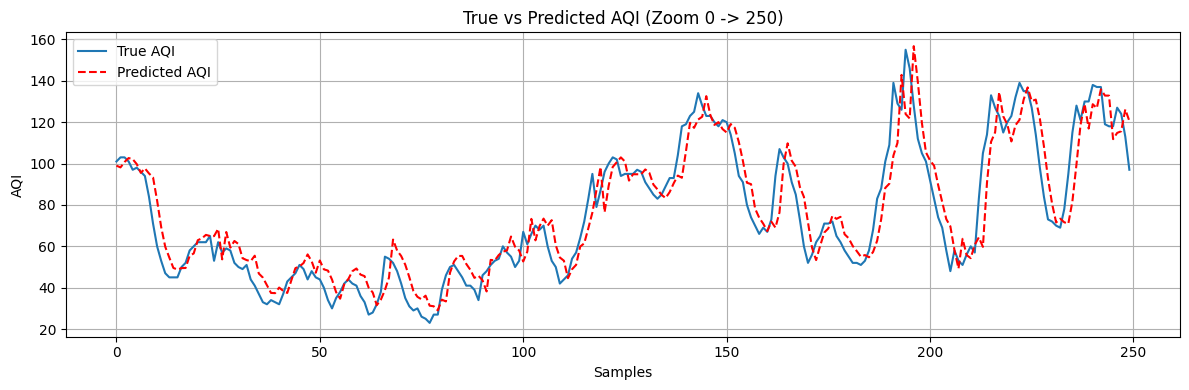

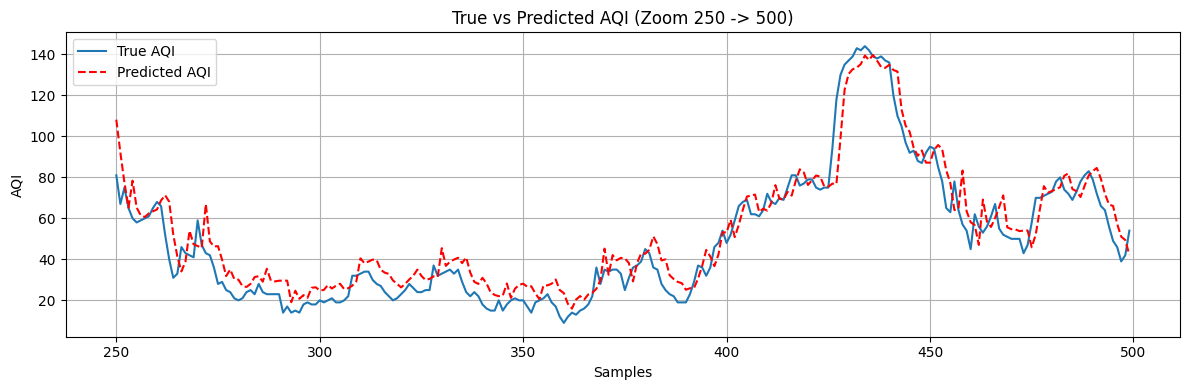

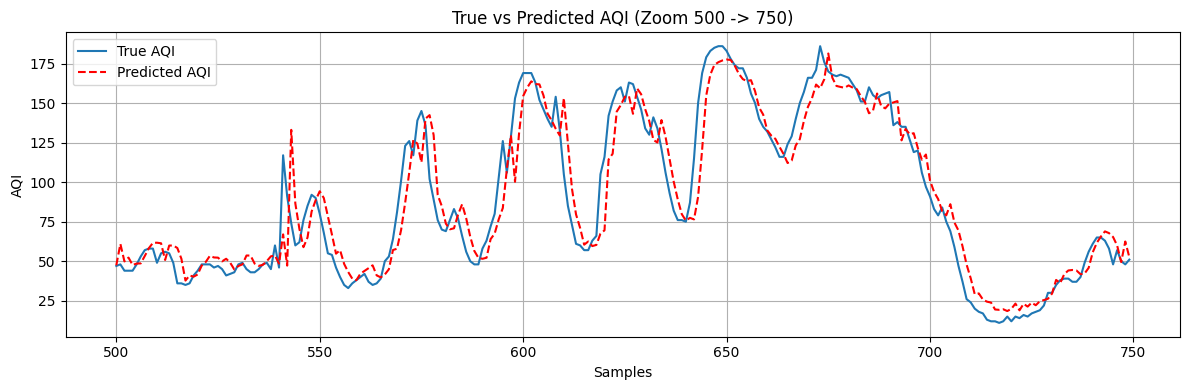

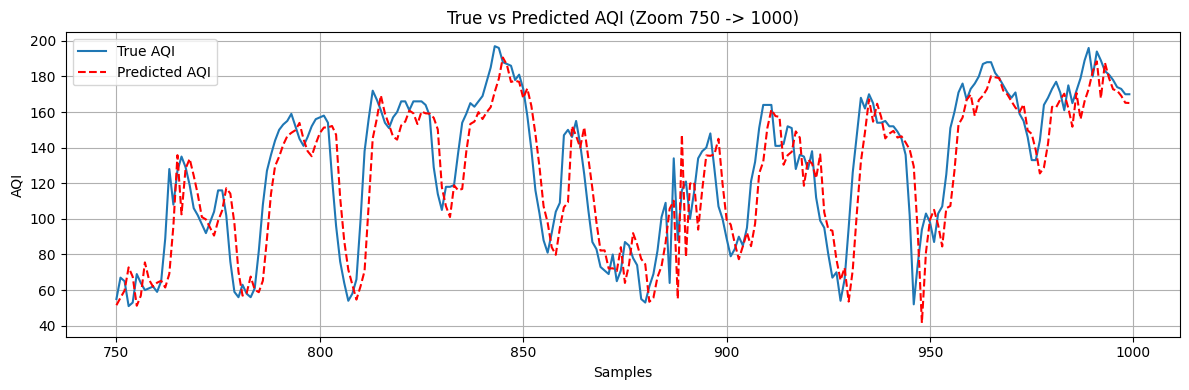

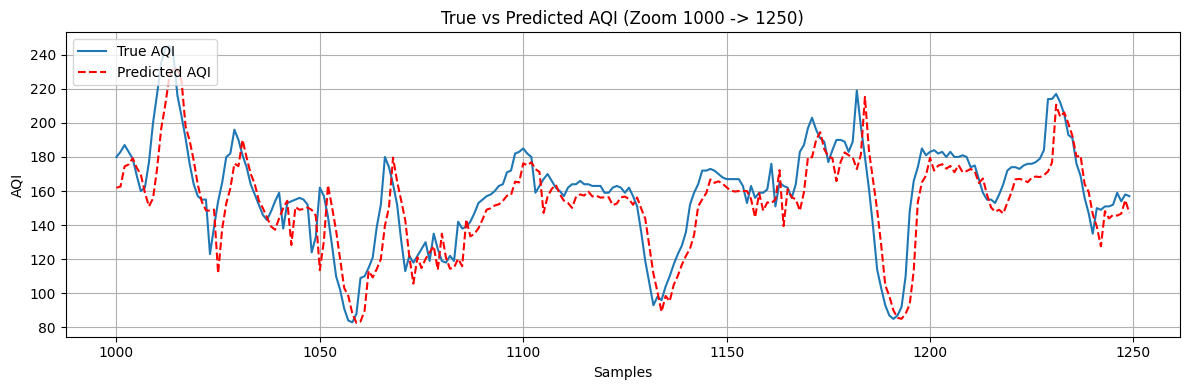

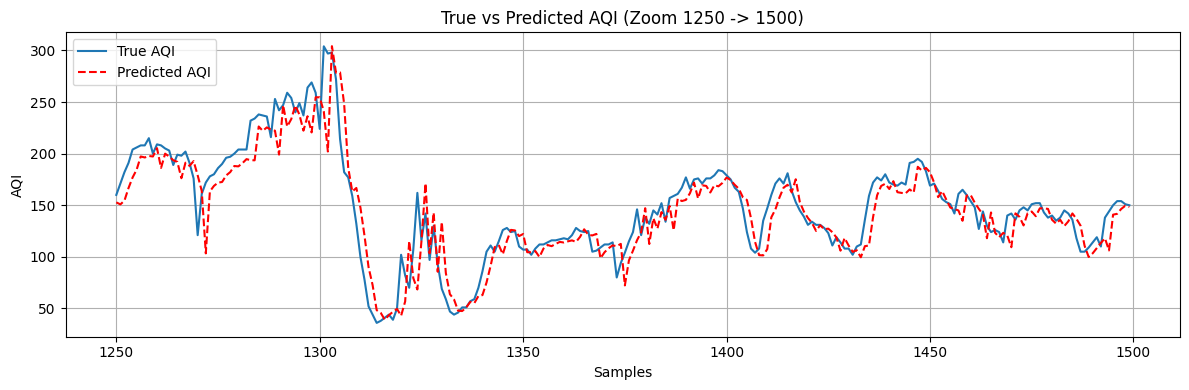

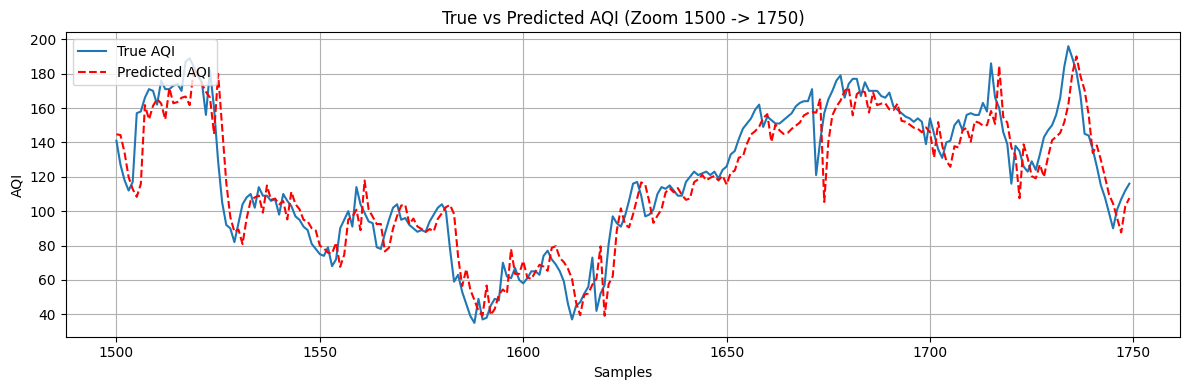

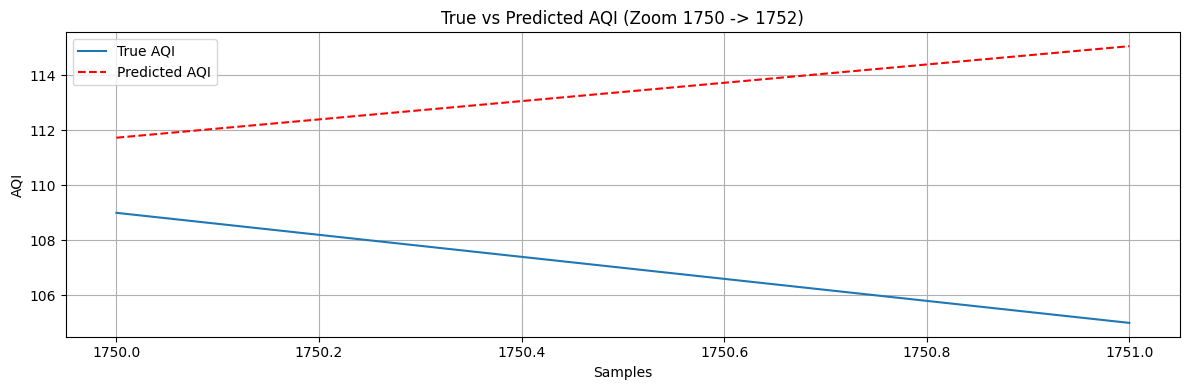

In [ ]:
window_size = 250

y_true = y_test.reset_index(drop=True)
y_pred = pd.Series(y_pred_lr)

for start in range(0, len(y_true), window_size):
    end = min(start + window_size, len(y_true))

    plt.figure(figsize=(12, 4))
    plt.plot(range(start, end), y_true.iloc[start:end], label="True AQI")
    plt.plot(range(start, end), y_pred.iloc[start:end], "r--", label="Predicted AQI")
    plt.title(f"True vs Predicted AQI (Zoom {start} -> {end})")
    plt.xlabel("Samples")
    plt.ylabel("AQI")
    plt.grid(True)
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
results.append(evaluate("RandomForest (lags 1-3)", y_test, y_pred_rf))


In [ ]:

try:
    from xgboost import XGBRegressor

    xgb = XGBRegressor(
        n_estimators=600,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42,
        objective="reg:squarederror"
    )
    xgb.fit(X_train, y_train)

    y_pred_xgb = xgb.predict(X_test)
    results.append(evaluate("XGBoost (lags 1-3)", y_test, y_pred_xgb))

except Exception as e:
    print("⚠️ Chưa chạy được XGBoost. Cài bằng: !pip install xgboost")
    print("Lỗi:", e)


In [ ]:
results_df = pd.DataFrame(results).sort_values("MSE")
results_df


,model,MSE,MAE,R2
1,Multiple Linear Regression (lags 1-3),262.642113,11.775221,0.912895
0,Baseline (AQI_t -> AQI_t+1),278.022260,11.626142,0.907794
3,XGBoost (lags 1-3),307.196057,12.430418,0.898119
2,RandomForest (lags 1-3),315.397653,12.722510,0.895399


from matplotlib import pyplot as plt
_df_0['index'].plot(kind='hist', bins=20, title='index')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['MSE'].plot(kind='hist', bins=20, title='MSE')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['MAE'].plot(kind='hist', bins=20, title='MAE')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['R2'].plot(kind='hist', bins=20, title='R2')
plt.gca().spines[['top', 'right',]].set_visible(False)

...

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_17['model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_17, x='MSE', y='model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_18['model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_18, x='MAE', y='model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_19['model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_19, x='R2', y='model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)